In [1]:
import xarray as xr
import matplotlib.pyplot as plt

from wk4proj.convvae_training import (
    ConvVAE,
    encode_latents,
    make_dataloaders,
    prepare_sst,
    set_seed,
    train_conv_vae,
)

In [ ]:
BETA = 1e-2

In [2]:
seed = 42
set_seed(seed)
ds = xr.open_dataset("data/data.grib")
sst_anomaly = prepare_sst(ds)
train_loader, validation_loader, standardizer, split = make_dataloaders(
    sst_anomaly, batch_size=16, validation_fraction=0.2, seed=seed
)

In [3]:
import numpy as np

values = sst_anomaly.values

print("Shape:", values.shape)
print("Finite values:", np.isfinite(values).sum())
print("NaN values:", np.isnan(values).sum())
print("Minimum:", np.nanmin(values))
print("Maximum:", np.nanmax(values))
print("Standard deviation:", np.nanstd(values))

Shape: (528, 256, 256)
Finite values: 27590112
NaN values: 7012896
Minimum: -13.294891
Maximum: 14.056061
Standard deviation: 0.66013217


In [ ]:
set_seed(seed)
model = ConvVAE(latent_dim=16)

history = train_conv_vae(
    model,
    train_loader,
    validation_loader,
    epochs=100,
    beta=BETA,
    learning_rate=3e-4,
    weight_decay=1e-4,
    patience=10,
    seed=seed,
)

latents = encode_latents(model, sst_anomaly, standardizer)

epoch 001/100: train=0.82958, validation=1.23737
epoch 002/100: train=0.75629, validation=0.99817
epoch 003/100: train=0.70920, validation=0.97408
epoch 004/100: train=0.66904, validation=0.86997
epoch 005/100: train=0.64566, validation=0.91216
epoch 006/100: train=0.63137, validation=0.84668
epoch 007/100: train=0.61395, validation=0.82848
epoch 008/100: train=0.60137, validation=0.82893
epoch 009/100: train=0.59142, validation=0.86251
epoch 010/100: train=0.58151, validation=0.85557
epoch 011/100: train=0.58084, validation=0.82323
epoch 012/100: train=0.58336, validation=0.82142
epoch 013/100: train=0.56982, validation=0.81890
epoch 014/100: train=0.55937, validation=0.80422
epoch 015/100: train=0.55462, validation=0.79869
epoch 016/100: train=0.54868, validation=0.79539
epoch 017/100: train=0.54591, validation=0.78651
epoch 018/100: train=0.54333, validation=0.81410
epoch 019/100: train=0.53725, validation=0.81174
epoch 020/100: train=0.53939, validation=0.82191
epoch 021/100: train

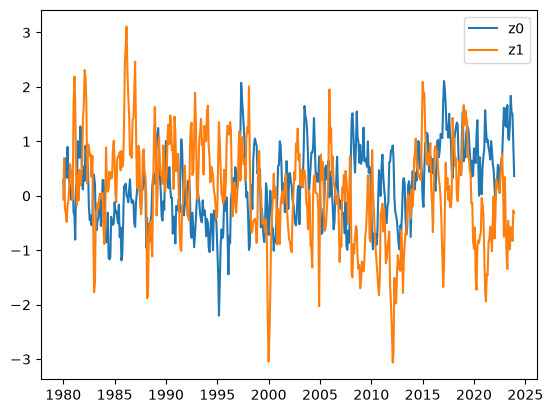

In [5]:
# Plot the leading two latent coordinates over time and inspect candidate
# El Nino/La Nina years against an ONI index.
fig, ax = plt.subplots()
for latent_index in (0,1):
    ax.plot(
        latents.time,
        latents.latent_mean.isel(latent=latent_index),
        label=f"z{latent_index}",
    )
ax.legend()

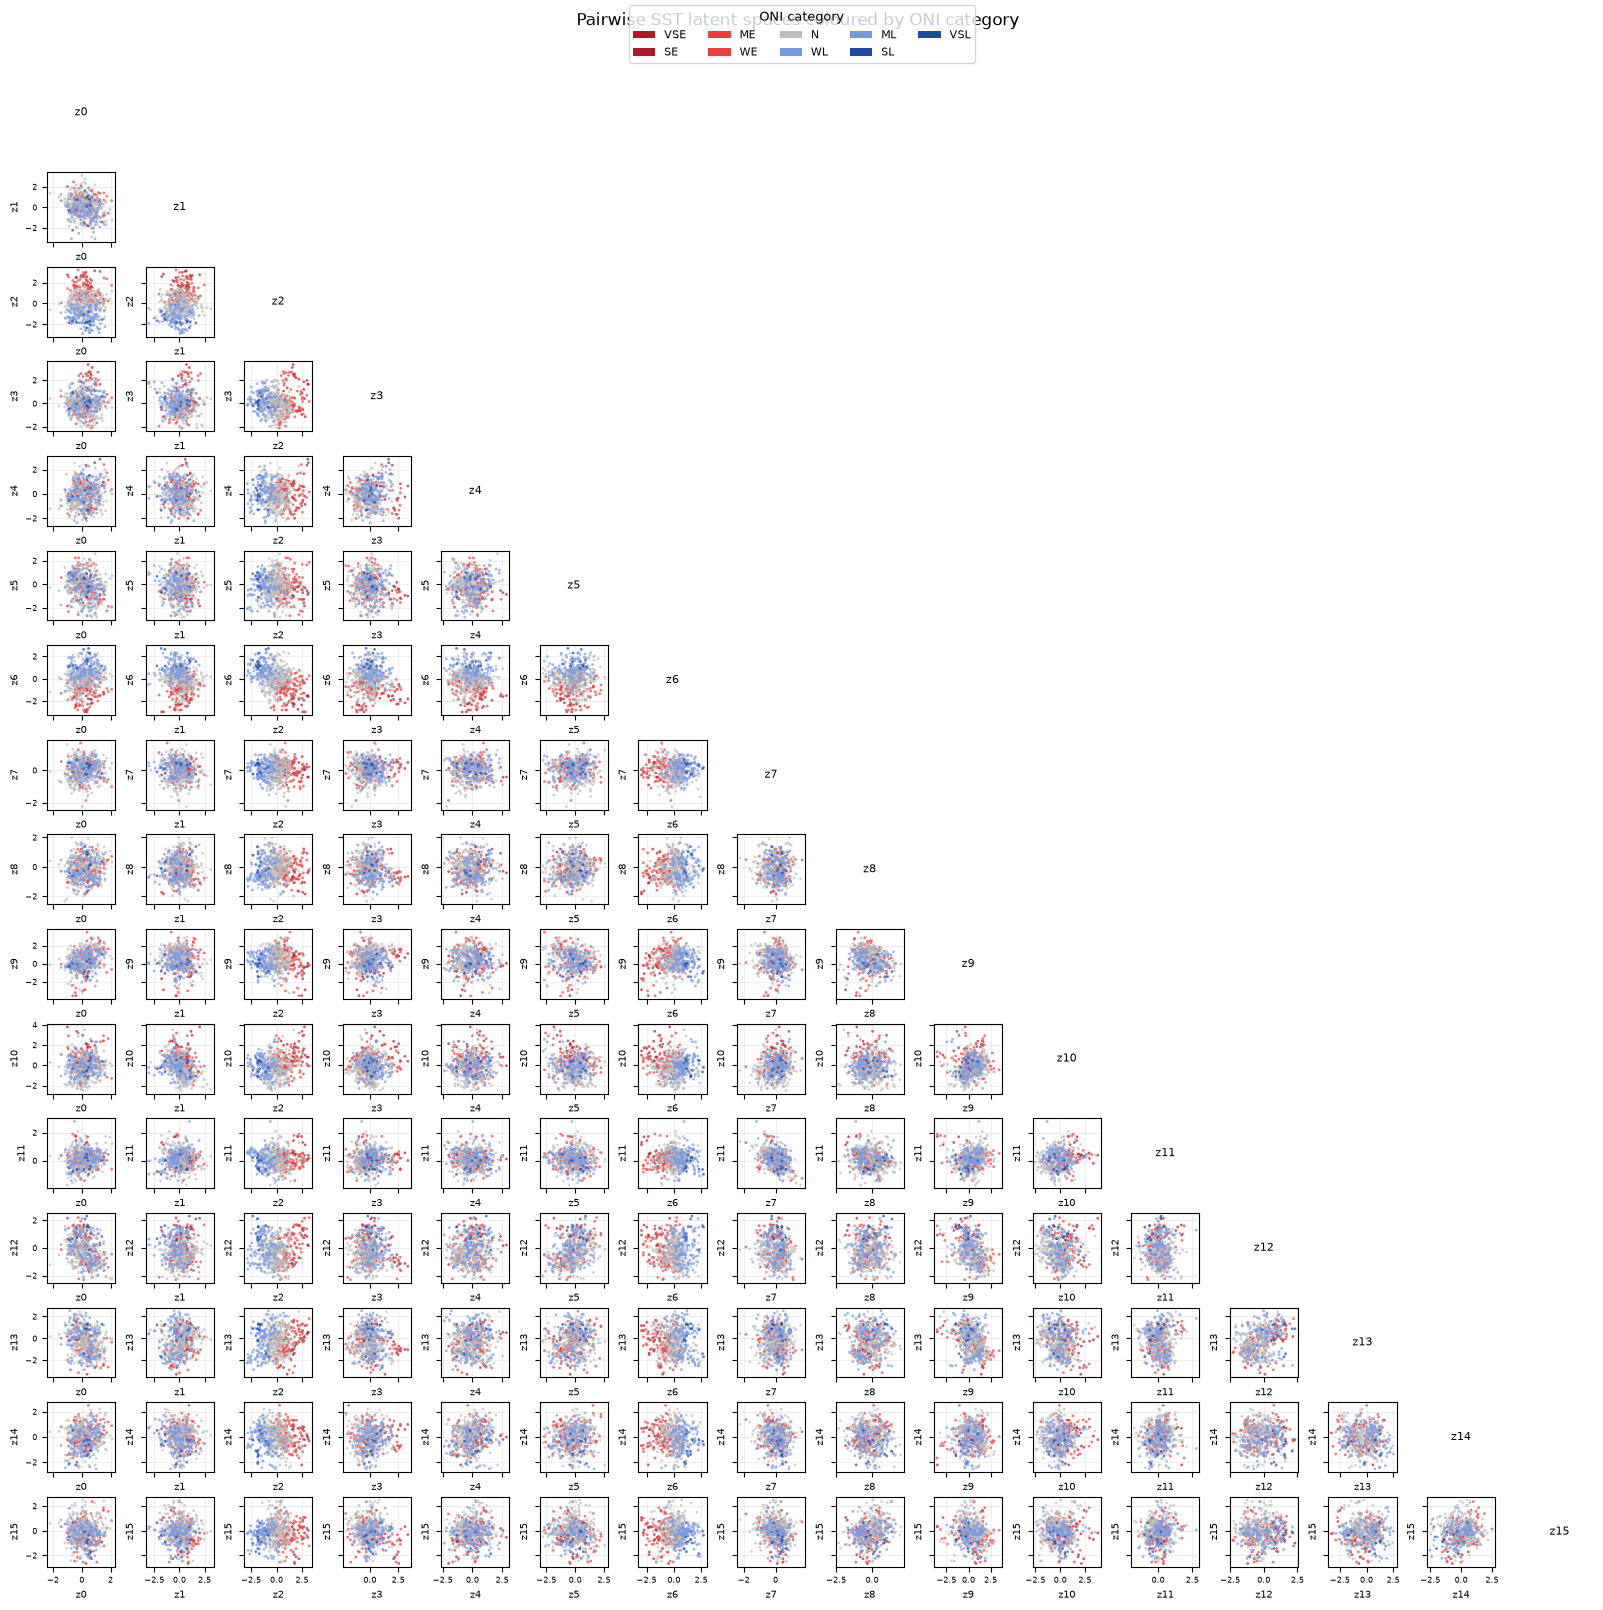

Matched 528 of 528 latent months to ONI categories


In [8]:
import csv
from collections import defaultdict
from pathlib import Path

oni_by_date = {}
with Path("data/oni.csv").open(newline="") as oni_file:
    for row in csv.DictReader(oni_file):
        oni_by_date[row["date"]] = row["category"]

latent_dates = latents.time.dt.strftime("%Y-%m-%d").values
categories = np.array([oni_by_date.get(date, "Unlabelled") for date in latent_dates])
matched = categories != "Unlabelled"

category_colours = {
    "VSE": "#b2182b",
    "SE": "#b2182b",
    "ME": "#ef3d3d",
    "WE": "#ef3d3d",
    "N": "#bdbdbd",
    "WL": "#7698e3",
    "ML": "#7698e3",
    "SL": "#214aa3",
    "VSL": "#214aa3",
    
}

from itertools import combinations
from matplotlib.patches import Patch

latent_values = latents.latent_mean.values[matched]
latent_dimension = latent_values.shape[1]
fig, axes = plt.subplots(
    latent_dimension,
    latent_dimension,
    figsize=(16, 16),
    sharex="col",
    sharey="row",
    squeeze=False,
)

for row, column in combinations(range(latent_dimension), 2):
    ax = axes[column, row]
    for category, colour in category_colours.items():
        selected = categories[matched] == category
        ax.scatter(
            latent_values[selected, row],
            latent_values[selected, column],
            color=colour,
            s=4,
            alpha=0.7,
            edgecolors="none",
            rasterized=True,
        )
    ax.set_xlabel(f"z{row}", fontsize=7)
    ax.set_ylabel(f"z{column}", fontsize=7)
    ax.tick_params(labelsize=6)
    ax.grid(alpha=0.2)

for index in range(latent_dimension):
    axes[index, index].text(
        0.5,
        0.5,
        f"z{index}",
        ha="center",
        va="center",
        fontsize=8,
        transform=axes[index, index].transAxes,
    )
    axes[index, index].set_axis_off()

for row in range(latent_dimension):
    for column in range(row + 1, latent_dimension):
        axes[row, column].set_visible(False)

legend_handles = [
    Patch(facecolor=colour, label=category)
    for category, colour in category_colours.items()
]
fig.legend(
    handles=legend_handles,
    title="ONI category",
    loc="upper center",
    ncol=5,
    fontsize=8,
    title_fontsize=9,
)
fig.suptitle("Pairwise SST latent spaces coloured by ONI category", y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.97), pad=0.3)
plt.show()

print(f"Matched {matched.sum()} of {len(matched)} latent months to ONI categories")

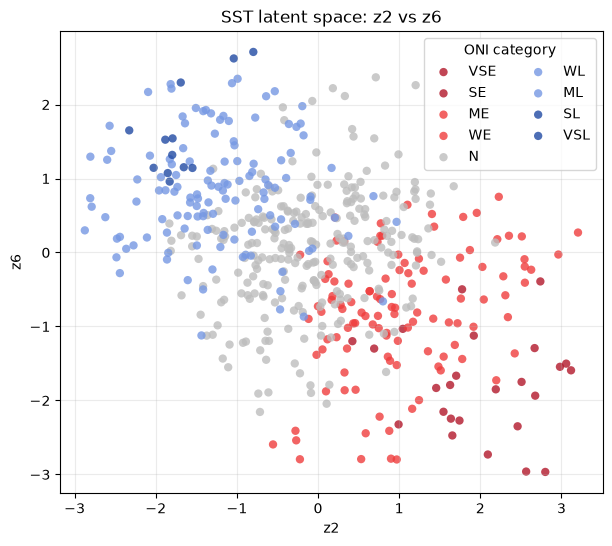

In [9]:
# Choose one pair of latent vectors to plot.
x_latent = 2    
y_latent = 6

if not (0 <= x_latent < latents.sizes["latent"]):
    raise ValueError(f"x_latent must be between 0 and {latents.sizes['latent'] - 1}")
if not (0 <= y_latent < latents.sizes["latent"]):
    raise ValueError(f"y_latent must be between 0 and {latents.sizes['latent'] - 1}")
if x_latent == y_latent:
    raise ValueError("x_latent and y_latent must be different")

fig, ax = plt.subplots(figsize=(7, 6))
for category, colour in category_colours.items():
    selected = matched & (categories == category)
    ax.scatter(
        latents.latent_mean.values[selected, x_latent],
        latents.latent_mean.values[selected, y_latent],
        color=colour,
        label=category,
        alpha=0.8,
        edgecolors="none",
    )

ax.set_xlabel(f"z{x_latent}")
ax.set_ylabel(f"z{y_latent}")
ax.set_title(f"SST latent space: z{x_latent} vs z{y_latent}")
ax.legend(title="ONI category", ncol=2)
ax.grid(alpha=0.25)
plt.show()


beta = 1e-3 :latents: 0,5
                        0,10
                        3,5
                        10,5